In [2]:
import pandas as pd
df = pd.read_csv('../data/raw/desafio_nps_fase_1.csv')
df['nps_cat'] = df['nps_score'].apply(lambda x: 'detrator' if x <= 6 else ('neutro' if x < 9 else 'promotor'))

df['had_cs_problem'] = (df['customer_service_contacts'] > 0) | (df['complaints_count'] > 0)

Hipótese: quando não há atraso, CS é o principal problema enfrentado pelos clientes, que afeta o NPS

In [3]:
df_sem_atraso = df[df['delivery_delay_days'] == 0]
df_sem_atraso_sem_contatos_suporte = df[(df['delivery_delay_days'] == 0) & (df['had_cs_problem'] == 0)]

<Axes: >

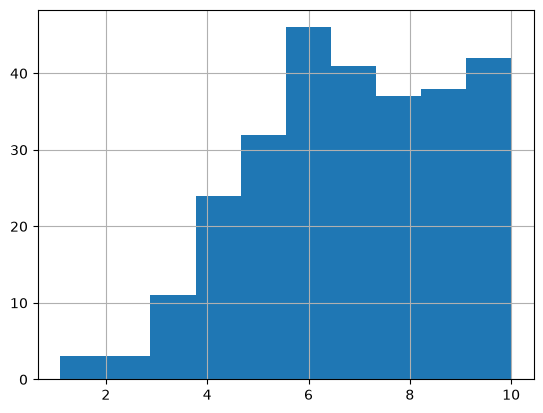

In [4]:
df_sem_atraso['nps_score'].hist()

<Axes: >

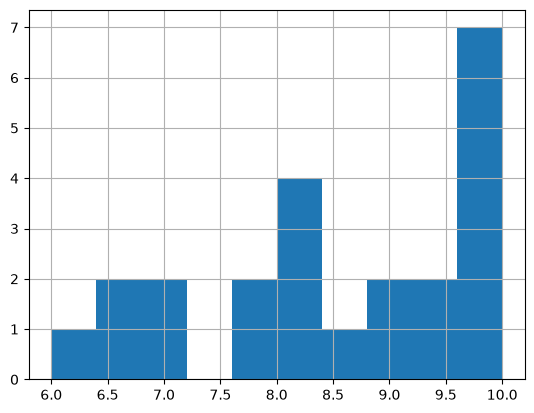

In [5]:
df_sem_atraso_sem_contatos_suporte['nps_score'].hist()

In [6]:
df_sem_atraso['nps_cat'].value_counts(normalize=True)

nps_cat
neutro      0.454874
detrator    0.364621
promotor    0.180505
Name: proportion, dtype: float64

In [7]:
df_sem_atraso_sem_contatos_suporte['nps_cat'].value_counts(normalize=True)

nps_cat
neutro      0.565217
promotor    0.391304
detrator    0.043478
Name: proportion, dtype: float64

In [8]:
df[df['had_cs_problem'] == 1]['nps_cat'].value_counts(normalize=True)

nps_cat
detrator    0.746871
neutro      0.212354
promotor    0.040775
Name: proportion, dtype: float64

In [9]:
df['had_cs_problem'].value_counts(normalize=True)

had_cs_problem
True     0.9908
False    0.0092
Name: proportion, dtype: float64

In [64]:
df['had_cs_problem'].value_counts(normalize=False)

had_cs_problem
True     2477
False      23
Name: count, dtype: int64

In [10]:
df['nps_cat'].value_counts(normalize=True)

nps_cat
detrator    0.7404
neutro      0.2156
promotor    0.0440
Name: proportion, dtype: float64

<Axes: >

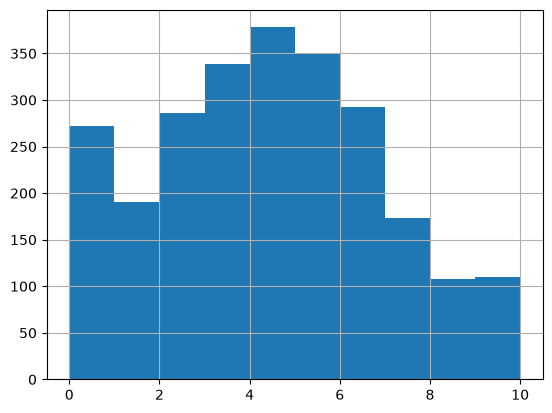

In [11]:
df['nps_score'].hist()

In [12]:
0.044 * 2500

110.0

In [13]:
df_cs_problem = df[df['had_cs_problem'] == 1]

In [14]:
df_cs_problem[['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'nps_cat',]].groupby('nps_cat').agg({'delivery_delay_days': ['mean', 'std', 'median'], 'customer_service_contacts': ['mean', 'std', 'median'], 'resolution_time_days': ['mean', 'std', 'median'], 'complaints_count': ['mean', 'std', 'median']}).T

nps_cat                           detrator    neutro  promotor
delivery_delay_days       mean    2.535676  1.326996  0.782178
                          std     1.429835  0.996906  0.782355
                          median  2.000000  1.000000  1.000000
customer_service_contacts mean    1.695135  1.119772  0.732673
                          std     1.265265  0.977318  0.847244
                          median  2.000000  1.000000  1.000000
resolution_time_days      mean    5.792432  4.760456  3.633663
                          std     3.419656  3.432566  3.155068
                          median  6.000000  4.000000  3.000000
complaints_count          mean    4.625405  2.982890  2.475248
                          std     1.622150  1.441458  1.360838
                          median  4.000000  3.000000  2.000000

Um cliente médio se torna detrator ao ter mais de um dia de atraso de entrega, ou ter que contatar o suporte 1.11x ou mais,ou  esperar por solução (de ticket) por 4.76 dias ou mais, ou ter que reclamar mais de 3 vezes.

Para neutro:
Típico:
1 dia de atraso
1 contato com CS
4 dias de resolução
3 reclamações

Para detrator:
Típico:
2 dias de atraso
2 contatos com CS
6 dias de resolução de ticket
4 reclamações

Essa progressão é real ou aleatória?

In [15]:
from scipy.stats import kruskal

promotor = df_cs_problem[df_cs_problem['nps_cat'] == 'promotor'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]
neutro = df_cs_problem[df_cs_problem['nps_cat'] == 'neutro'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]
detrator = df_cs_problem[df_cs_problem['nps_cat'] == 'detrator'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]

In [16]:
kruskal(promotor, neutro, detrator)

KruskalResult(statistic=array([424.33328356, 138.02958758,  66.86769704, 484.91330728]), pvalue=array([7.19777442e-093, 1.06477020e-030, 3.01900672e-015, 5.03979908e-106]))

In [17]:
df['detrator'] = df['nps_cat'] == 'detrator'

<Axes: xlabel='customer_service_contacts'>

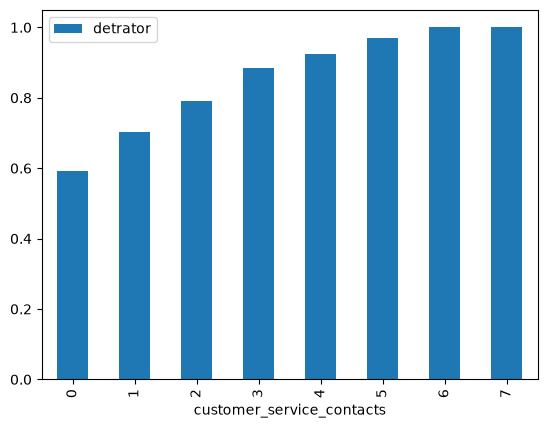

In [18]:
df[['customer_service_contacts', 'detrator']].groupby('customer_service_contacts').mean().plot(kind='bar')

<Axes: xlabel='resolution_time_days'>

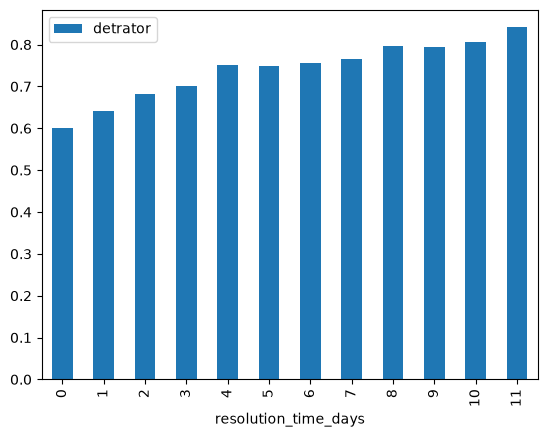

In [19]:
df[['resolution_time_days', 'detrator']].groupby('resolution_time_days').mean().plot(kind='bar')

                  detrator
complaints_count          
0                 0.043478
1                 0.081967
2                 0.433213
3                 0.676529
4                 0.811667
5                 0.882883
6                 0.936090
7                 0.934911
8                 1.000000
9                 1.000000
10                0.909091
11                1.000000


<Axes: xlabel='complaints_count'>

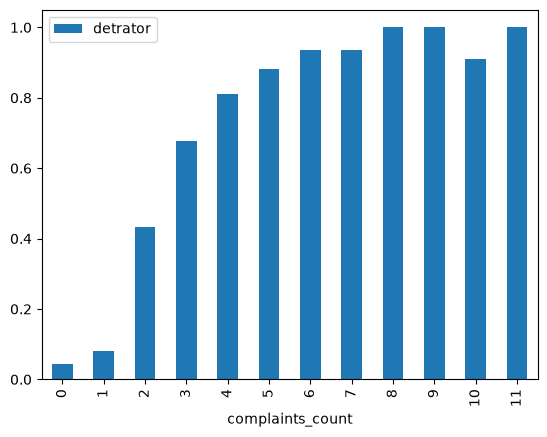

In [20]:

print(df[['complaints_count', 'detrator']].groupby('complaints_count').mean())
df[['complaints_count', 'detrator']].groupby('complaints_count').mean().plot(kind='bar')

In [21]:
df[['complaints_count', 'customer_service_contacts', 'resolution_time_days']].corr(method='spearman')

,complaints_count,customer_service_contacts,resolution_time_days
complaints_count,1.000000,0.735918,0.024351
customer_service_contacts,0.735918,1.000000,0.015807
resolution_time_days,0.024351,0.015807,1.000000


In [25]:
df_cs_problem.columns

Index(['customer_id', 'customer_age', 'customer_region',
       'customer_tenure_months', 'order_id', 'order_value', 'items_quantity',
       'discount_value', 'payment_installments', 'delivery_time_days',
       'delivery_delay_days', 'freight_value', 'delivery_attempts',
       'customer_service_contacts', 'resolution_time_days', 'nps_score',
       'repeat_purchase_30d', 'complaints_count', 'csat_internal_score',
       'nps_cat', 'had_cs_problem'],
      dtype='str')

In [29]:
from scipy.stats import kruskal

promotor = df_cs_problem[df_cs_problem['nps_cat'] == 'promotor'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]
neutro = df_cs_problem[df_cs_problem['nps_cat'] == 'neutro'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]
detrator = df_cs_problem[df_cs_problem['nps_cat'] == 'detrator'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]

In [30]:
kruskal(promotor, neutro, detrator)

KruskalResult(statistic=array([0.49656096, 0.65071009, 2.51599816, 3.94782408, 1.08601256,
       0.72177994]), pvalue=array([0.7801411 , 0.72227087, 0.28422216, 0.13891236, 0.58099898,
       0.69705569]))

In [31]:
tabela_regiao = pd.crosstab(df_cs_problem['customer_region'], df_cs_problem['nps_cat'])

In [32]:
from scipy.stats import chi2_contingency
chi2_contingency(tabela_regiao)

Chi2ContingencyResult(statistic=np.float64(2.9121806203417573), pvalue=np.float64(0.9397471198029157), dof=8, expected_freq=array([[347.29511506,  98.74444893,  18.96043601],
       [358.49818329, 101.92975373,  19.57206298],
       [374.92935002, 106.60153411,  20.46911587],
       [386.87928946, 109.99919257,  21.12151797],
       [382.39806217, 108.72507065,  20.87686718]]))

In [45]:
df_bins = df_cs_problem[['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'nps_cat'  ]].copy()

In [46]:
df_bins['customer_age_bin'] = pd.cut(df_bins['customer_age'], bins=[0, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels=['0-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90', '91-100'])

In [47]:
df_bins['tenure_bin'] = pd.cut(df_bins['customer_tenure_months'], bins=[0, 12, 24, 36, 48, 60, 72, 84, 96, 108, 120], labels=['0-12', '13-24', '25-36', '37-48', '49-60', '61-72', '73-84', '85-96', '97-108', '109-120'])
df_bins['order_value_bin'] = pd.qcut(df_bins['order_value'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])


In [48]:
promotor_bin = df_bins[df_bins['nps_cat'] == 'promotor'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]
neutro_bin = df_bins[df_bins['nps_cat'] == 'neutro'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]
detrator_bin = df_bins[df_bins['nps_cat'] == 'detrator'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]

In [51]:
df_bins['detrator'] = df_bins['nps_cat'] == 'detrator'

In [52]:
df_bins.groupby('customer_age_bin')['detrator'].mean()

customer_age_bin
0-20     0.794702
21-30    0.723596
31-40    0.776000
41-50    0.742798
51-60    0.748963
61-70    0.721550
Name: detrator, dtype: float64

In [53]:
df_bins.groupby('tenure_bin')['detrator'].mean()

tenure_bin
0-12       0.773109
13-24      0.719512
25-36      0.738589
37-48      0.743478
49-60      0.745968
61-72      0.692623
73-84      0.745704
85-96      0.773279
97-108     0.774059
109-120    0.762846
Name: detrator, dtype: float64

In [54]:
df_bins.groupby('order_value_bin')['detrator'].mean()

order_value_bin
Q1    0.766129
Q2    0.736672
Q3    0.756058
Q4    0.728595
Name: detrator, dtype: float64

In [58]:
cross_age_bin = pd.crosstab(df_bins['order_value_bin'], df_bins['nps_cat'])

chi2_contingency(cross_age_bin)

Chi2ContingencyResult(statistic=np.float64(5.124159847963158), pvalue=np.float64(0.527990299354522), dof=6, expected_freq=array([[463.06015341, 131.65926524,  25.28058135],
       [462.3132822 , 131.44691159,  25.23980622],
       [462.3132822 , 131.44691159,  25.23980622],
       [462.3132822 , 131.44691159,  25.23980622]]))

In [63]:
df_bins['customer_age_bin'].value_counts()

customer_age_bin
31-40     500
41-50     486
51-60     482
21-30     445
61-70     413
0-20      151
71-80       0
81-90       0
91-100      0
Name: count, dtype: int64

In [67]:
df['order_id'].unique()

array([50001, 50002, 50003, ..., 52498, 52499, 52500], shape=(2500,))